# Projet final : les résultats d'examens

**Équipe :** (nom de l'équipe et des 5 membres)

Un réseau de 25 écoles (fictives) vous confie les résultats de ses candidats aux examens de fin d'études secondaires, en 2024 et 2025. Le fichier sort tel quel du secrétariat. Le directeur veut savoir quelles filières, quels secteurs et quelles communes réussissent, et lesquelles décrochent. Un candidat réussit avec une moyenne d'au moins 10 sur 20.

Ce notebook montre **votre démarche** : chaque étape dit ce que vous cherchez, le code, le résultat et ce que vous en concluez. Les graphiques doivent être visibles : avant de pousser, **Restart**, puis **Run All**.

Le tableau de bord (`app.py`) reprend ensuite vos résultats pour le décideur.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

brut = pd.read_csv("donnees/resultats_brut.csv")

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, et toutes les écritures d'une même valeur dans les colonnes de texte. Notez chaque problème trouvé : vous le corrigerez à l'étape 2.

In [2]:
brut.shape, brut.duplicated().sum()

((1529, 6), np.int64(25))

In [3]:
brut["code_ecole"].unique()

<ArrowStringArray>
[ 'E01',  'E02',  'e02',  'E03',  'E04',  'e04',  'E05',  'E06',  'E07',
 ' E07',  'E08', ' E08', 'E08 ',  'E09',  'e09', ' E09',  'E10', ' E10',
  'E11',  'e11', ' E11',  'E12',  'E13', ' E13',  'E14',  'e14', 'E14 ',
  'E15',  'E16',  'e16',  'E17',  'e17',  'E18', 'E18 ',  'e18',  'E19',
  'E20',  'e20', ' E20',  'E21', 'E21 ',  'e21',  'E22', 'E22 ',  'e22',
  'E23', ' E23',  'e23',  'E24', ' E24', ' E01', 'E01 ', 'E03 ', ' E04',
 'E07 ',  'e07', 'E09 ', 'E10 ',  'e10',  'e12', ' E14', 'E17 ', ' E17',
 'E20 ',  'e24',  'E25', ' E25']
Length: 67, dtype: str

In [4]:
brut["filiere"].unique()

<ArrowStringArray>
[ 'SVT',  'ses',  'SES',  'LLA',  'smp',  'SMP',  'svt', 'LLA ', 'SMP ',
 ' SMP', 'SES ', ' SVT', 'SVT ', ' LLA',  'lla', ' SES']
Length: 16, dtype: str

In [5]:
brut.isna().sum()

candidat       0
annee          0
code_ecole     0
filiere        0
sexe           0
moyenne       18
dtype: int64

In [6]:
brut.dtypes

candidat        str
annee         int64
code_ecole      str
filiere         str
sexe            str
moyenne         str
dtype: object

In [7]:
pd.to_numeric(brut["moyenne"], errors="coerce").isna().sum()

np.int64(178)

In [8]:
texte = brut["moyenne"]
texte[pd.to_numeric(texte, errors="coerce").isna() & texte.notna()].head(10)

40        11,6
43     11.2/20
57         8,8
63        10,2
66     13.7/20
68        12,4
79     10.3/20
90     14.0/20
98     11.4/20
111        8,5
Name: moyenne, dtype: str

## Problèmes remarqués
25 doublons, 18 lignes sans moyenne

Plusieurs écritures pour les mêmes code école et filières

Moyennes de type chaines de caractères au lieu de valeurs numériques (178 moyennes ne povant être converties en numérique)

## 2. Nettoyage

Une copie `propre`, puis une cellule par problème, en comptant les lignes avant et après chaque suppression. Dites ce que vous supprimez et pourquoi.

**Contrôle :** à la fin, `propre.shape` vaut `(1486, 6)`, sans valeur manquante ni doublon, avec 4 valeurs dans `filiere`, 2 valeurs dans `sexe`.

In [9]:
propre = brut.copy()
propre.shape[0]

1529

Suppression des valeurs doublon

In [10]:
propre = propre.drop_duplicates()
propre.shape[0]

1504

Suppression de toutes les lignes sans moyenne

In [11]:
propre = propre.dropna(subset="moyenne")
propre.shape[0]

1486

Correction des écritures des codes école (On passe de 67 écritures différentes à 25)

In [12]:
propre["code_ecole"] = propre["code_ecole"].str.strip().str.title()
propre["code_ecole"].nunique(), brut["code_ecole"].nunique()

(25, 67)

Correction des écritures des filières (On passe de 16 écritures différentes à 4)

In [13]:
propre["filiere"] = propre["filiere"].str.strip().str.upper()
propre["filiere"].nunique(), brut["filiere"].nunique()

(4, 16)

Correction des moyennes

Certaines moyennes sont écrites avec des nombres à virgule, d'autres s'écrivaient avec un /20
On enlève le /20 et on remplace les "," par des "."

In [14]:
propre["moyenne"] = propre["moyenne"].str.strip().str.replace("/20", "").str.replace(",", ".")
propre["moyenne"] = pd.to_numeric(propre["moyenne"], errors="coerce")
propre.dtypes["moyenne"]


dtype('float64')

Colonne Calculée (1 Si l'élève a réussi, 0 sinon)

In [15]:
propre["reussi"] = (propre["moyenne"] >= 10).astype(str)
propre["reussi"] = propre["reussi"].str.replace("True", "1").str.replace("False", "0")
propre["reussi"] = propre["reussi"].astype(int)
propre.head(10)

,candidat,annee,code_ecole,filiere,sexe,moyenne,reussi
0,C24-0001,2024,E01,SVT,F,13.5,1
1,C24-0002,2024,E01,SES,M,9.1,0
2,C24-0003,2024,E01,SES,M,9.3,0
3,C24-0004,2024,E01,LLA,M,9.3,0
4,C24-0005,2024,E01,SMP,F,9.2,0
5,C24-0006,2024,E01,SVT,F,9.9,0
6,C24-0007,2024,E01,SES,F,11.4,1
7,C24-0008,2024,E01,SMP,F,12.2,1
8,C24-0009,2024,E01,SES,F,13.0,1
9,C24-0010,2024,E01,SVT,F,7.4,0


## 3. Jointures

Joignez `propre` avec `ecoles.csv`, `communes.csv`, et ajoutez les colonnes calculées dont vous aurez besoin. Comptez les lignes avant et après chaque `merge`.

**Contrôle :** 1486 lignes après les jointures, autant qu'avant.

In [16]:
ecoles = pd.read_csv("donnees/ecoles.csv")
communes = pd.read_csv("donnees/communes.csv")

In [17]:
combi_propre_ecole = propre.merge(ecoles, on="code_ecole", how="left")
combi_propre_ecole.shape[0]

1486

In [18]:
complet = combi_propre_ecole.merge(communes, on="commune", how="left")
complet.shape[0]

1486

Enregistrez le tableau complet : c'est le fichier que lit le tableau de bord.

```python
complet.to_csv("donnees/resultats_propre.csv", index=False)
```

In [19]:
complet.to_csv("donnees/resultats_propre.csv", index=False)

## 4. Quelles filières réussissent le mieux ? L'écart entre filières est-il le même en 2024 et en 2025 ?

In [20]:
(((complet.groupby("filiere")["reussi"].sum()) / (complet.groupby("filiere")["reussi"].size()))*100).round(2).sort_values(ascending=False)

filiere
SMP    62.72
SVT    50.35
SES    46.28
LLA    42.09
Name: reussi, dtype: float64

In [21]:
complet_2024 = complet[complet["annee"] == 2024]
eva_2024 = (((complet_2024.groupby("filiere")["reussi"].sum()) / (complet_2024.groupby("filiere")["reussi"].size()))*100).round(2).sort_values(ascending=False)

In [22]:
complet_2025 = complet[complet["annee"] == 2025]
eva_2025 = (((complet_2025.groupby("filiere")["reussi"].sum()) / (complet_2025.groupby("filiere")["reussi"].size()))*100).round(2).sort_values(ascending=False)

In [23]:
eva_filiere_2024_2025 = pd.concat([eva_2024, eva_2025], axis=1)
eva_filiere_2024_2025.columns = ["2024", "2025"]
eva_filiere_2024_2025

,2024,2025
filiere,,
SMP,60.33,65.42
SVT,52.82,48.25
LLA,47.27,35.61
SES,45.86,46.69


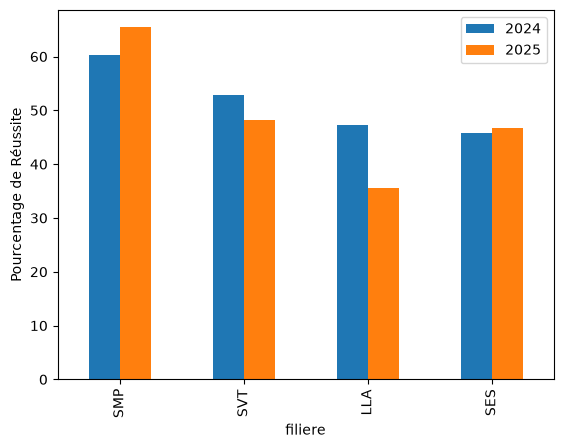

In [49]:
graphe_eva_filiere = eva_filiere_2024_2025.plot(kind = "bar", ylabel = "Pourcentage de Réussite")

**Ce qu'on en conclut :**

Les filières qui réussissent le mieux sont SMP (65.42% de réussite) et SVT (48.25% de réussite). L'écart entre les filières est différent de part les variations en pourcentage (Le SES classé 4ème en 2024 est 3ème en 2025, sa place étant prise par le LLA qui bascule en 4ème avec 35.61% de réussite).

## 5. Le secteur de l'école (public, privé, congréganiste) fait-il une différence ? Montrez-le avec un graphique.

In [25]:
eva_secteur = (((complet.groupby("secteur")["reussi"].sum()) / (complet.groupby("secteur")["reussi"].size()))*100).round(2).sort_values(ascending=False)
eva_secteur

secteur
Congréganiste    70.92
Privé            53.55
Public           37.85
Name: reussi, dtype: float64

Text(0, 0.5, 'Pourcentage de réussite des élèves')

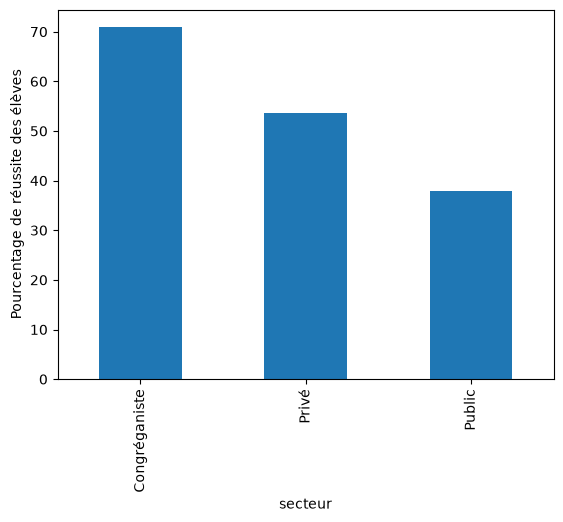

In [26]:
ax = eva_secteur.plot(kind = "bar")
ax.set_ylabel("Pourcentage de réussite des élèves")

**Ce qu'on en conclut :**

Oui, le secteur de l'école fait une différence. Car les écoles congréganistes ont un taux de réussite plus élevé (70.92%) et le secteur public a le plus bas taux de réussite (37.85%)

## 6. Quelles communes et quels départements décrochent ? Lesquels progressent ?

In [27]:
complet_2024 = complet[complet["annee"] == 2024]
eva_commune_2024 = (((complet_2024.groupby("commune")["reussi"].sum()) / (complet_2024.groupby("commune")["reussi"].size()))*100).round(2).sort_values(ascending=False)

In [29]:
complet_2025 = complet[complet["annee"] == 2025]
eva_commune_2025 = (((complet_2025.groupby("commune")["reussi"].sum()) / (complet_2025.groupby("commune")["reussi"].size()))*100).round(2).sort_values(ascending=False)

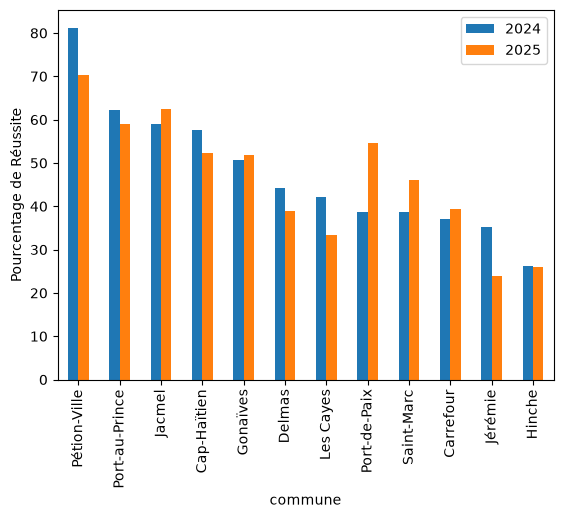

In [30]:
eva_commune= pd.concat([eva_commune_2024, eva_commune_2025], axis=1)
eva_commune.columns = ["2024", "2025"]
graphe_eva_commune = eva_commune.plot(kind="bar", ylabel = "Pourcentage de Réussite")

In [31]:
ratio_commune = (eva_commune_2025 - eva_commune_2024).sort_values(ascending=False)
ratio_commune

commune
Port-de-Paix      15.95
Saint-Marc         7.58
Jacmel             3.60
Carrefour          2.43
Gonaïves           1.02
Hinche            -0.30
Port-au-Prince    -3.24
Cap-Haïtien       -5.20
Delmas            -5.34
Les Cayes         -8.89
Pétion-Ville     -11.04
Jérémie          -11.48
Name: reussi, dtype: float64

In [32]:
eva_departement_2024 = (((complet_2024.groupby("departement")["reussi"].sum()) / (complet_2024.groupby("departement")["reussi"].size()))*100).round(2).sort_values(ascending=False)
eva_departement_2025 = (((complet_2025.groupby("departement")["reussi"].sum()) / (complet_2025.groupby("departement")["reussi"].size()))*100).round(2).sort_values(ascending=False)

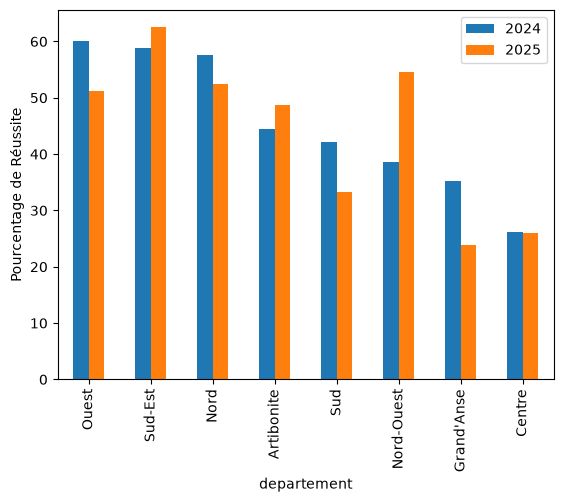

In [34]:
eva_departement = pd.concat([eva_departement_2024, eva_departement_2025], axis=1)
eva_departement.columns = ["2024", "2025"]
graphe_eva_departement = eva_departement.plot(kind="bar", ylabel="Pourcentage de Réussite")

In [35]:
ratio_departement = (eva_departement_2025 - eva_departement_2024).sort_values(ascending=False)
ratio_departement

departement
Nord-Ouest    15.95
Artibonite     4.32
Sud-Est        3.60
Centre        -0.30
Nord          -5.20
Sud           -8.89
Ouest         -8.91
Grand'Anse   -11.48
Name: reussi, dtype: float64

**Ce qu'on en conclut :**

Les communes qui progressent sont : Port-de-Paix (progression la plus forte), Saint-Marc, Jacmel, Carrefour et Gonaives.

Les communes qui décrochent sont : Hinche, Port-au-Prince, Cap-Haitien, Delmas, Les Cayes, Pétion-Ville et Jérémie (décrochage le plus fort)

Les départements qui progressent sont : Le Nord-Ouest (progression la plus forte), l'Artibonite et le Sud-Est

Les départements qui décrochent sont le Centre, le Nord, le Sud, l'Ouest et la Grand'Anse (décrochage le plus fort)

## 7. Filles et garçons réussissent-ils de la même façon, dans chaque filière ?

In [39]:
eva_sexe = (((complet.groupby("sexe")["reussi"]).sum() / (complet.groupby("sexe")["reussi"]).size())*100).round(2)
eva_sexe

sexe
F    49.74
M    48.46
Name: reussi, dtype: float64

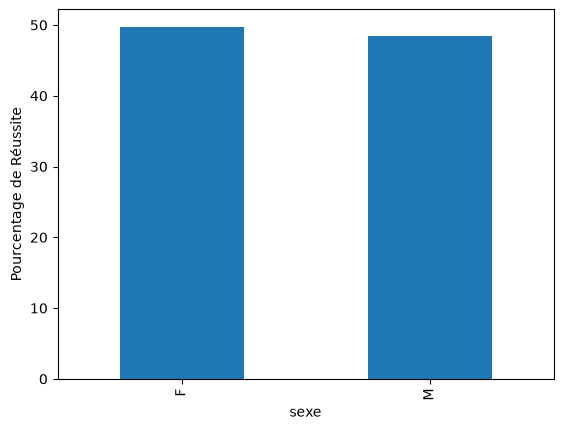

In [40]:
graphe_sexe = eva_sexe.plot(kind="bar", ylabel="Pourcentage de Réussite")

In [46]:
eva_sexe_filiere = pd.concat([complet.groupby(["filiere", "sexe"]).size(), complet.groupby(["filiere", "sexe"])["reussi"].sum()], axis=1)
eva_sexe_filiere.columns = ["Total", "Reussi"]
eva_sexe_filiere

Total  Reussi
filiere sexe               
LLA     F       161      72
        M       136      53
SES     F       253     117
        M       285     132
SMP     F       129      79
        M        99      64
SVT     F       231     117
        M       192      96

In [47]:
eva_sexe_filiere["Reussite_%"] = ((eva_sexe_filiere["Reussi"] / eva_sexe_filiere["Total"])*100).round(2)
eva_sexe_filiere

Total  Reussi  Reussite_%
filiere sexe                           
LLA     F       161      72       44.72
        M       136      53       38.97
SES     F       253     117       46.25
        M       285     132       46.32
SMP     F       129      79       61.24
        M        99      64       64.65
SVT     F       231     117       50.65
        M       192      96       50.00

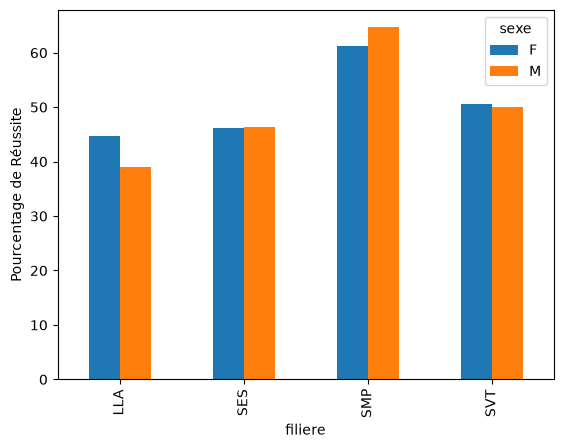

In [48]:
del eva_sexe_filiere["Total"]
del eva_sexe_filiere["Reussi"]
eva_sexe_filiere = eva_sexe_filiere["Reussite_%"].unstack()
graphe_eva_sexe_filiere = eva_sexe_filiere.plot(kind="bar", ylabel = "Pourcentage de Réussite")

**Ce qu'on en conclut :**

Indépendemment de la filière, les filles ont un taux de réussite légèrement supérieur (49.74% contre 48.46% pour les garçons).

En LLA, les filles ont un meilleur taux de réussite que les garçons, mais en SMP, cette tendance s'inverse.

En SES et en SVT, les chances sont "presques" égales, avec une parité presque parfaite.

## 8. Un code d'école des résultats est absent de `ecoles.csv` : lequel, combien de candidats, et comment l'avez-vous traité ?

Code école absent de ecoles.csv

In [50]:
set(complet["code_ecole"].unique()).difference(ecoles["code_ecole"].unique())

{'E25'}

Nombre de candidats concernés

In [51]:
complet[complet["code_ecole"] == "E25"].shape[0]

27

**Ce qu'on en conclut :**

Le code E25 est présent parmi les codes écoles dans les résultats, mais n'existe pas dans ecoles.csv. Cette absence perturbe les résultats de 27 candidats, empêchant d'obtenir les informations de leurs écoles, commune etc...

Pour le bien de l'analyse, on considère les valeurs avec le code de l'école manquante lors de l'évaluation des filières, mais on les ignore lors de l'évaluation des communes et départements

## 9. Conclusion

Cinq phrases au plus : ce qu'il faut retenir, ce que les données ne permettent pas de dire, ce qu'il faudrait mesurer ensuite.

Les filières réussissant le mieux sont SMP et SVT. Le secteur de l'école peut influer sur le taux de réussite de l'élève (constat que les écoles congréganistes ont un meilleur taux de réussite.) 

Les communes qui progressent le mieux sont Port-de-Paix, Saint-Marc et Jacmel, les départements qui progressent le mieux sont le Nord-Ouest et l'Artibonite. 

Les filles ont un taux de réussite légèrement supérieur généralement, mais cette tendance varie selon la filière observée. 

Toutefois, toutes les observations décrites ici ne sont que des estimations, elles ne permettent pas vraiment d'établir une corrélation entre différents facteurs comme la filière, le secteur etc... et la réussite des étudiants.

Pour approfondir cette étude, il serait intéressant de mesurer l'influence de l'assiduité, des conditions d'apprentissage et des ressources pédagogiques, ces informations permettraient de mieux comprendre les facteurs qui influencent les résultats scolaires.